# 🏥 Семинар 5. Оценка моделей и борьба с переобучением

**Построить модель — это полдела**. Главная задача data scientist'а — сделать так,
чтобы модель хорошо работала **на новых пациентах**, которых она раньше не видела.

Сегодня разберём:
1. Что значит «хорошая модель» (обобщающая способность)
2. Переобучение и недообучение
3. Дилемма смещения-дисперсии
4. Регуляризация (L1, L2, ElasticNet)
5. Train / Validation / Test
6. Кросс-валидация

In [ ]:
# @title Загрузка данных и подготовка
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression, Ridge, Lasso, ElasticNet, LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, recall_score, classification_report
from sklearn.model_selection import learning_curve

# Датасет: рак молочной железы
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = 1 - data.target  # 1 = рак (болен), 0 = здоров

print(f'📊 Датасет: {X.shape[0]} пациентов, {X.shape[1]} признаков')
print(f'Доля больных: {y.mean():.1%}')

## 🎯 1. Обобщающая способность (Generalization)

Хорошая модель — это не та, которая идеально запомнила обучающую выборку.
Это та, которая **уловила общие закономерности** и может применять их к новым данным.

### Критерии хорошей модели:

| Критерий | Что это значит | Пример в медицине |
|---|---|---|
| **Обобщающая способность** | Работает на новых данных, не запомнила шум | Модель, обученная в клинике Москвы, работает и в клинике Новосибирска |
| **Интерпретируемость** | Понятно, почему модель приняла решение | Врач может объяснить пациенту: «у вас высокий холестерин, поэтому риск» |
| **Устойчивость (robustness)** | Не «ломается» от выбросов и шума | Не паникует, если один анализ сделан с ошибкой |
| **Правильная метрика** | Оцениваем то, что важно для задачи | Для скрининга рака Recall |

> 💡 **Принцип Occam's Razor (Бритва Оккама):** среди моделей с одинаковой производительностью выбирай самую простую.

In [55]:

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, recall_score, roc_auc_score,
                             roc_curve, confusion_matrix, classification_report)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- 1. Разделяем данные: обучаем на одном, проверяем на другом ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'Обучающая: {X_train.shape[0]} пациентов')
print(f'Тестовая:  {X_test.shape[0]} пациентов (модель их НЕ видела)')

# --- 2. Собираем модель (масштабирование + логистическая регрессия) ---
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])
pipe.fit(X_train, y_train)

# --- 3. Предсказания: метки и вероятности ---
y_pred  = pipe.predict(X_test)
y_proba = pipe.predict_proba(X_test)[:, 1]   # вероятность класса "болен"

# --- 4. Метрики — «из коробки», одной строкой каждая ---
print('\n=== МЕТРИКИ ===')
print(f'Accuracy на train: {pipe.score(X_train, y_train):.3f}')
print(f'Accuracy на test:  {accuracy_score(y_test, y_pred):.3f}')
print(f'Recall  на test:   {recall_score(y_test, y_pred):.3f}')
print(f'ROC-AUC на test:   {roc_auc_score(y_test, y_proba):.3f}')
print('\nClassification report:')
print(classification_report(y_test, y_pred, target_names=['здоров', 'болен']))

Обучающая: 455 пациентов
Тестовая:  114 пациентов (модель их НЕ видела)

=== МЕТРИКИ ===
Accuracy на train: 0.989
Accuracy на test:  0.982
Recall  на test:   0.986
ROC-AUC на test:   0.995

Classification report:
              precision    recall  f1-score   support

      здоров       0.98      0.98      0.98        42
       болен       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



Если accuracy на train ≈ accuracy на test — модель обобщила. Если на train 0.99, а на test 0.75 — модель переобучилась (запомнила шум).

## 📉 2. Недообучение vs Переобучение

Представьте, что студент готовится к экзамену по истории медицины.

| Ситуация | Что делает студент | Результат на экзамене |
|---|---|---|
| 🟡 **Недообучение (underfitting)** | Почти не учил, знает только «было что-то про Гиппократа» | ❌ Провал: не может ответить ни на один вопрос |
| 🟢 **Идеальная модель** | Выучил закономерности: «если X, то Y, потому что...» | ✅ Отлично: решает новые задачи |
| 🔴 **Переобучение (overfitting)** | Выучил наизусть ВСЕ билеты прошлого года дословно | ❌ Провал: на новых вопросах теряется, т.к. зазубрил, а не понял |

### Как это выглядит математически:

- **Недообучение**: модель слишком простая (например, прямая линия для нелинейных данных). Высокая ошибка и на train, и на test.
- **Переобучение**: модель слишком сложная (например, полином 20-й степени). На train — почти 0 ошибки, на test — катастрофа.

> 🎯 **Главный признак переобучения**: огромный разрыв между качеством на обучении и на тесте.

## 🔁 Вспомним: линейная регрессия

Вы уже знаете модель:

$$
\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_n x_n
$$

**Вопрос на подумать:** «линейная» — это про что?

- (а) Про то, что график — прямая линия?
- (б) Про то, что \(y) линейно зависит от весов \(w_k\)?



w0 = 1.27, w1 = 1.88
Модель: y = w0 + w1*x — это ЛИНИЯ, потому что у нас ОДИН признак x


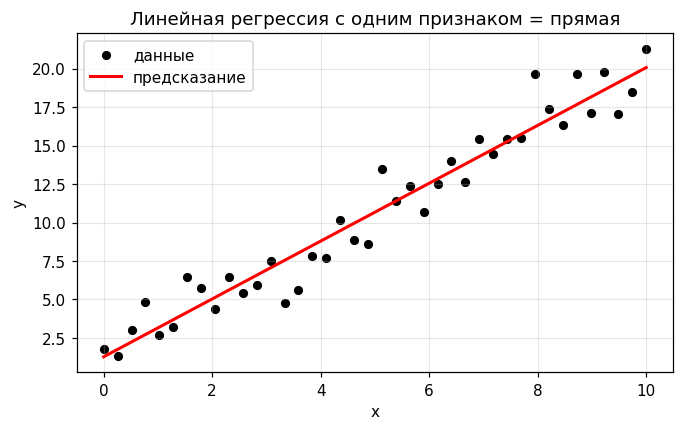

In [56]:
# @title

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

np.random.seed(42)
x = np.linspace(0, 10, 40)
y = 2 * x + 1 + np.random.normal(0, 1.5, x.size)

model = LinearRegression().fit(x.reshape(-1, 1), y)

print(f'w0 = {model.intercept_:.2f}, w1 = {model.coef_[0]:.2f}')
print('Модель: y = w0 + w1*x — это ЛИНИЯ, потому что у нас ОДИН признак x')

plt.figure(figsize=(7, 4))
plt.scatter(x, y, c='black', s=25, label='данные')
plt.plot(x, model.predict(x.reshape(-1, 1)), 'r-', lw=2, label='предсказание')
plt.xlabel('x'); plt.ylabel('y')
plt.title('Линейная регрессия с одним признаком = прямая')
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [57]:
# Добавим ВТОРОЙ признак — и всё та же LinearRegression
# Но график уже не прямая, а плоскость в 3D
np.random.seed(42)
n = 60
x1 = np.random.uniform(0, 10, n)
x2 = np.random.uniform(0, 10, n)
y2 = 1.5 * x1 - 2 * x2 + 3 + np.random.normal(0, 1, n)

X_2d = np.column_stack([x1, x2])
m2 = LinearRegression().fit(X_2d, y2)

print(f'w0 = {m2.intercept_:.2f}, w = {m2.coef_}')
print('\nЭто всё ещё LinearRegression, но в пространстве (x1, x2, y) — плоскость, а не прямая.')
print('Линейность — в том, что y = w0 + w1*x1 + w2*x2.')

w0 = 2.94, w = [ 1.45005654 -1.95381224]

Это всё ещё LinearRegression, но в пространстве (x1, x2, y) — плоскость, а не прямая.
Линейность — в том, что y = w0 + w1*x1 + w2*x2.


## 🤔 А что если в качестве второго признака взять... \(x^2\)?

Никто не запрещает объявить **новый признак как функцию старого**:

$$
x_1 = x, \quad x_2 = x^2
$$

Тогда та же самая линейная регрессия ищет:

$$
\hat{y} = w_0 + w_1 x + w_2 x^2
$$

- По-прежнему **линейно по весам** \(w_k\) — значит, это та же `LinearRegression`.
- Но по \(x\) это уже **парабола** — график гнётся!

**Гипотеза:** модель ни разу не поменялась. Поменялся только **набор признаков**.
Проверим.

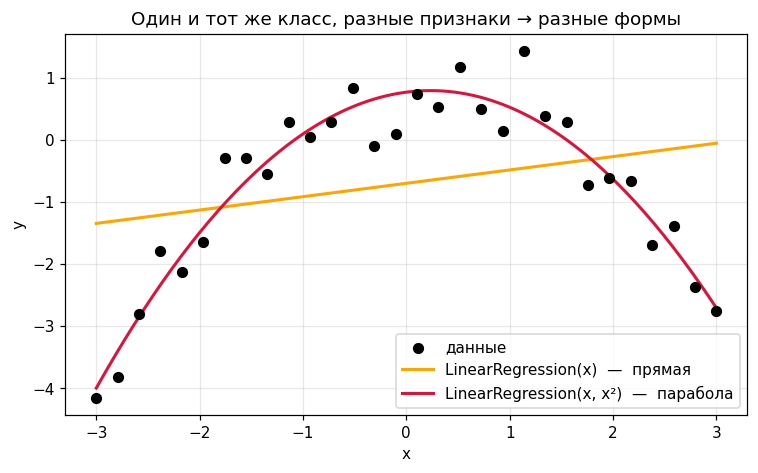

=== Модель A (только x) ===
  .coef_     = [0.21507912]
  .intercept_= -0.698   → y = -0.70 + 0.22*x

=== Модель B (x и x²) ===
  .coef_     = [ 0.21507912 -0.45757882]
  .intercept_= 0.770   → y = 0.77 + 0.22*x + -0.46*x²

🚨 Модель B — это ТОТ ЖЕ класс LinearRegression.
   Полиномиальная регрессия = LinearRegression + полиномиальные признаки.


In [58]:
# @title
# Данные с явной нелинейностью: горб
np.random.seed(42)
x = np.linspace(-3, 3, 30)
y_true = 1 - 0.5 * x**2 + 0.3 * x     # парабола
y = y_true + np.random.normal(0, 0.5, x.size)

# ---------- Модель A: обычная линейная регрессия (только x) ----------
mA = LinearRegression().fit(x.reshape(-1, 1), y)

# ---------- Модель B: тот же класс, но на [x, x^2] ----------
X_poly = np.column_stack([x, x**2])
mB = LinearRegression().fit(X_poly, y)

# ---------- Визуализация ----------
x_plot = np.linspace(-3, 3, 200).reshape(-1, 1)
X_plot_poly = np.column_stack([x_plot.ravel(), x_plot.ravel()**2])

plt.figure(figsize=(8, 4.5))
plt.scatter(x, y, c='black', s=40, zorder=5, label='данные')
plt.plot(x_plot, mA.predict(x_plot), 'orange', lw=2, label='LinearRegression(x)  —  прямая')
plt.plot(x_plot, mB.predict(X_plot_poly), 'crimson', lw=2, label='LinearRegression(x, x²)  —  парабола')
plt.xlabel('x'); plt.ylabel('y')
plt.title('Один и тот же класс, разные признаки → разные формы')
plt.legend(); plt.grid(alpha=0.3); plt.show()

print('=== Модель A (только x) ===')
print(f'  .coef_     = {mA.coef_}')
print(f'  .intercept_= {mA.intercept_:.3f}   → y = {mA.intercept_:.2f} + {mA.coef_[0]:.2f}*x')

print('\n=== Модель B (x и x²) ===')
print(f'  .coef_     = {mB.coef_}')
print(f'  .intercept_= {mB.intercept_:.3f}   → y = {mB.intercept_:.2f} + {mB.coef_[0]:.2f}*x + {mB.coef_[1]:.2f}*x²')

print('\n🚨 Модель B — это ТОТ ЖЕ класс LinearRegression.')
print('   Полиномиальная регрессия = LinearRegression + полиномиальные признаки.')

Результат одинаковый. PolynomialFeatures — это не модель, это преобразователь признаков (как StandardScaler). Модель по-прежнему LinearRegression.

# 🧩 Как `PolynomialFeatures(degree=3)` строит признаки — разбираем на 3 признаках

Возьмём три исходных признака: \(x_1, x_2, x_3\).
Что произойдёт, если попросить `PolynomialFeatures(degree=3)`?

## Правило, которое надо запомнить

`PolynomialFeatures` строит **все произведения вида**

$$
x_1^{a_1}\, x_2^{a_2}\, x_3^{a_3}, \qquad \text{где } a_1 + a_2 + a_3 \le 3,
$$


Ключевое слово — **«все»**. Не только «\(x_1^2\)» и «\(x_2^3\)» по отдельности, но и **все комбинации разных признаков**, у которых суммарная степень не превышает \(3\).

---

## Шаг 1. Разложим по суммарной степени

Суммарная степень \(\;a_1 + a_2 + a_3\;\) может быть **1, 2 или 3**.

### 🟢 Степень 1 — только сами признаки

$$
x_1,\quad x_2,\quad x_3
$$

**3 члена.** Никаких произведений — просто исходные столбцы.

---

### 🟡 Степень 2 — квадраты и попарные произведения

Сюда попадают все мономы, где сумма степеней ровно 2:

| Моном | Почему попадает |
|---|---|
| \(x_1^2\) | \(2+0+0=2\) ✅ |
| \(x_2^2\) | \(0+2+0=2\) ✅ |
| \(x_3^2\) | \(0+0+2=2\) ✅ |
| \(x_1 x_2\) | \(1+1+0=2\) ✅ |
| \(x_1 x_3\) | \(1+0+1=2\) ✅ |
| \(x_2 x_3\) | \(0+1+1=2\) ✅ |

**6 членов.** Обратите внимание — здесь есть **и квадраты, и произведения разных признаков**. Это и есть «взаимодействия».

---

### 🔴 Степень 3 — кубы, «квадрат × другой» и «все три сразу»

| Моном | Почему попадает |
|---|---|
| \(x_1^3\) | \(3+0+0=3\) ✅ |
| \(x_2^3\) | \(0+3+0=3\) ✅ |
| \(x_3^3\) | \(0+0+3=3\) ✅ |
| \(x_1^2 x_2\) | \(2+1+0=3\) ✅ |
| \(x_1^2 x_3\) | \(2+0+1=3\) ✅ |
| \(x_2^2 x_1\) | \(1+2+0=3\) ✅ |
| \(x_2^2 x_3\) | \(0+2+1=3\) ✅ |
| \(x_3^2 x_1\) | \(1+0+2=3\) ✅ |
| \(x_3^2 x_2\) | \(0+1+2=3\) ✅ |
| \(x_1 x_2 x_3\) | \(1+1+1=3\) ✅ |

**10 членов.** Тут уже три типа: чистые кубы (3), «квадрат одного × другой» (6) и «все три сразу» (1).

---

## Шаг 2. Собираем всё вместе

**Итого:** \(3 + 6 + 10 = 19\) признаков.

Общая формула числа мономов:

$$
\binom{n + d}{d} - 1 = \binom{3 + 3}{3} - 1 = \binom{6}{3} - 1 = 20 - 1 = 19.
$$

Модель, обученная на этих 19 столбцах, будет выглядеть так:

$$
\hat{y} = w_0
+ w_1 x_1 + w_2 x_2 + w_3 x_3
+ w_4 x_1^2 + w_5 x_2^2 + w_6 x_3^2
+ w_7 x_1 x_2 + w_8 x_1 x_3 + w_9 x_2 x_3
+ w_{10} x_1^3 + w_{11} x_2^3 + w_{12} x_3^3
+ w_{13} x_1^2 x_2 + w_{14} x_1^2 x_3 + w_{15} x_2^2 x_1 + w_{16} x_2^2 x_3 + w_{17} x_3^2 x_1 + w_{18} x_3^2 x_2
+ w_{19} x_1 x_2 x_3.
$$

(Класс модели — всё та же `LinearRegression`. «Нелинейность» целиком пришла из признаков.)

---

In [59]:
# ========== МИНИ-ЗАДАНИЕ ==========
# 1) Обучите LinearRegression на [x] и на [x, x^2, ..., x^15] на одних данных
# 2) Сравните MSE на train и на test
# 3) Ответьте: где недообучение, где переобучение, почему?

import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# ---------- 1. ГЕНЕРАЦИЯ ДАННЫХ ----------
# Фиксируем seed — чтобы результат был воспроизводимым
np.random.seed(1)

# 40 точек равномерно на [0, 10]. Это исходный признак x (одномерный).
x = np.linspace(0, 10, 40) #Аналогия сгенерируй мне 40 объектов, у каждого один признак x, равномерно разбросанный по отрезку [0, 10]
 #, применяется чаще всего для наглядной показательности

# Истинная зависимость: sin(x) + линейный тренд 0.3*x + гауссов шум σ=0.3
#   sin(x)          — НЕлинейная часть; простая линейная модель её не поймает
#   0.3*x           — линейный тренд; линейная модель его поймает
#   normal(0, 0.3)  — необучаемый шум (любая модель ошибётся минимум на его дисперсию ≈ 0.09)
y = np.sin(x) + 0.3 * x + np.random.normal(0, 0.3, x.size)

# ---------- 2. TRAIN/TEST SPLIT ----------
# x.reshape(-1, 1): sklearn ждёт 2D-массив признаков (n_samples, n_features).
# test_size=0.3 → 12 объектов в тесте, 28 в трейне (от 40).
# random_state=0 фиксирует разбиение, чтобы результаты были стабильны.
X_tr, X_te, y_tr, y_te = train_test_split(
    x.reshape(-1, 1), y, test_size=0.3, random_state=0
)

# ---------- 3. ЦИКЛ ПО СТЕПЕНЯМ ПОЛИНОМА ----------
# deg=1  → обычная линейная регрессия (низкая сложность модели)
# deg=3  → кубическая (средняя сложность)
# deg=15 → очень высокая сложность (риск переобучения)
for deg in [1, 3, 15]:
    # PolynomialFeatures преобразует один признак x в набор [x, x^2, ..., x^deg].
    # include_bias=False — константный столбец НЕ добавляем:
    # свободный член (intercept) сам добавит LinearRegression.
    poly = PolynomialFeatures(degree=deg, include_bias=False)

    # fit_transform на ТРЕЙНЕ: подгоняем преобразование (ничего не подгоняется,
    # для PolynomialFeatures это тривиально) И сразу применяем к трейну.
    Xtr_p = poly.fit_transform(X_tr)

    # transform на ТЕСТЕ: используем ТОЛЬКО параметры, выученные на трейне.
    # Здесь нельзя вызывать fit — иначе будет утечка данных (data leakage).
    Xte_p = poly.transform(X_te)

    # Обучаем обычную линейную регрессию на расширенных признаках.
    m = LinearRegression().fit(Xtr_p, y_tr)

    # Считаем MSE = (1/n) * Σ (y_true - y_pred)^2 отдельно на трейне и тесте.
    # Если MSE_test >> MSE_train → переобучение.
    # Если ОБА MSE высокие и близки → недообучение.
    print(f'degree={deg:>2}: train MSE = {mean_squared_error(y_tr, m.predict(Xtr_p)):.4f} '
          f'| test MSE = {mean_squared_error(y_te, m.predict(Xte_p)):.4f}')

print('\n❓ Вопросы:')
print('   • На каком degree тестовая ошибка минимальна?')
print('   • На каком degree разрыв train/test максимальный?')
print('   • Если бы вы не имели test-выборки, какой degree выбрали бы по train?')
print('   • Почему это опасно? (мостик к следующей теме — регуляризации)')

degree= 1: train MSE = 0.3469 | test MSE = 0.6684
degree= 3: train MSE = 0.2982 | test MSE = 0.4995
degree=15: train MSE = 0.0817 | test MSE = 0.1934

❓ Вопросы:
   • На каком degree тестовая ошибка минимальна?
   • На каком degree разрыв train/test максимальный?
   • Если бы вы не имели test-выборки, какой degree выбрали бы по train?
   • Почему это опасно? (мостик к следующей теме — регуляризации)


Графическое представление

In [60]:
# @title
# ========== Импорты ==========
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import mean_squared_error

# Настройка отображения
%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
np.random.seed(42)

print('✅ Всё готово')

✅ Всё готово


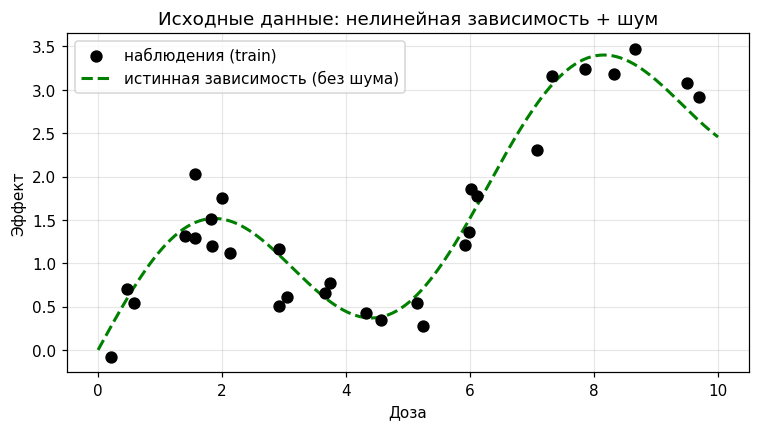

Точек в выборке: 30
Стандартное отклонение шума: 0.27


In [61]:
# @title
# ========== Генерируем данные ==========
# Истинная зависимость: effect = sin(dose) + 0.3 * dose
# Плюс немного шума — как в реальном измерении

n = 30
dose = np.sort(np.random.uniform(0, 10, n))
true_effect = np.sin(dose) + 0.3 * dose
noise = np.random.normal(0, 0.3, n)
effect = true_effect + noise

X = dose.reshape(-1, 1)   # sklearn ждёт 2D
y = effect

# Для гладкого рисования
x_plot = np.linspace(0, 10, 300).reshape(-1, 1)

# Посмотрим на данные
plt.figure(figsize=(8, 4))
plt.scatter(dose, effect, s=50, c='black', zorder=5, label='наблюдения (train)')
plt.plot(x_plot, np.sin(x_plot.ravel()) + 0.3 * x_plot.ravel(),
         'g--', lw=2, label='истинная зависимость (без шума)')
plt.xlabel('Доза'); plt.ylabel('Эффект')
plt.legend(); plt.grid(alpha=0.3)
plt.title('Исходные данные: нелинейная зависимость + шум')
plt.show()

print(f'Точек в выборке: {n}')
print(f'Стандартное отклонение шума: {noise.std():.2f}')

## 🧩 Повтор: Откуда берутся квадраты, кубы и т.д.

`PolynomialFeatures(degree=d)` — это **явное преобразование признаков**:
из одного столбца $x$ создаёт столбцы $x, x^2, x^3, \dots, x^d$.

$$
x \;\longrightarrow\; [\,x,\; x^2,\; x^3,\; \dots,\; x^d\,]
$$

Потом обычная **линейная регрессия** ищет веса:

$$
\hat{y} = w_0 + w_1 x + w_2 x^2 + \dots + w_d x^d
$$

Это **линейно по весам** $w_k$ (потому и «линейная регрессия»),
но **нелинейно по $x$** — отсюда изгибы.

> 💡 Полиномиальная регрессия = линейная регрессия + полиномиальные признаки.
> Отдельного алгоритма нет.

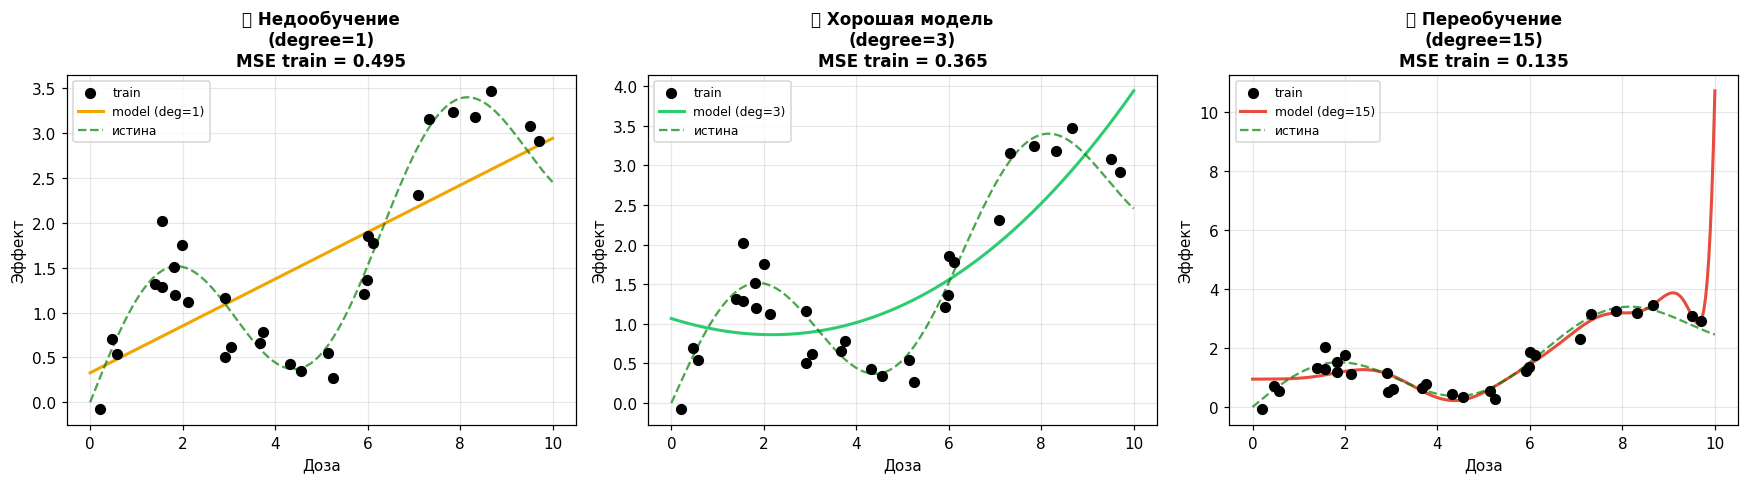

🧠 Что видно:
• Слева: прямая — не может изогнуться, ошибка и на train большая (недообучение)
• Центр: плавная кривая — уловила форму истины, разумная ошибка
• Справа: зигзаги — прошла через ВСЕ точки, MSE на train ≈ 0 (переобучение)


In [62]:
# @title
# ========== 3 модели разной сложности на одних данных ==========

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
degrees = [1, 3, 15]
titles = [
    '🟡 Недообучение\n(degree=1)',
    '🟢 Хорошая модель\n(degree=3)',
    '🔴 Переобучение\n(degree=15)'
]
colors = ['#f0a500', '#2ecc71', '#e74c3c']

for ax, title, deg, col in zip(axes, titles, degrees, colors):
    # 1) строим полиномиальные признаки
    poly = PolynomialFeatures(degree=deg, include_bias=False)
    X_poly = poly.fit_transform(X)

    # 2) обучаем линейную регрессию на них
    model = LinearRegression().fit(X_poly, y)

    # 3) предсказания
    y_pred_train = model.predict(X_poly)
    y_pred_plot = model.predict(poly.transform(x_plot))

    # 4) MSE на train
    mse_train = mean_squared_error(y, y_pred_train)

    # 5) рисуем
    ax.scatter(X, y, s=40, c='black', zorder=5, label='train')
    ax.plot(x_plot, y_pred_plot, color=col, lw=2, label=f'model (deg={deg})')
    ax.plot(x_plot, np.sin(x_plot.ravel()) + 0.3 * x_plot.ravel(),
            'g--', lw=1.5, alpha=0.7, label='истина')

    ax.set_title(f'{title}\nMSE train = {mse_train:.3f}',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Доза'); ax.set_ylabel('Эффект')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print('🧠 Что видно:')
print('• Слева: прямая — не может изогнуться, ошибка и на train большая (недообучение)')
print('• Центр: плавная кривая — уловила форму истины, разумная ошибка')
print('• Справа: зигзаги — прошла через ВСЕ точки, MSE на train ≈ 0 (переобучение)')

  degree |    MSE train |     MSE test |     разрыв
----------------------------------------------------
       1 |       0.4502 |       0.6434 |     0.1932
       2 |       0.3524 |       0.4136 |     0.0612
       3 |       0.3438 |       0.4508 |     0.1070
       5 |       0.0679 |       0.0538 |    -0.0141
       8 |       0.0560 |       0.1723 |     0.1163
      12 |       0.0352 |     655.8447 |   655.8095
      15 |       0.0320 |  736188.0038 | 736187.9717
      20 |       0.0277 | 7786903987.0769 | 7786903987.0492


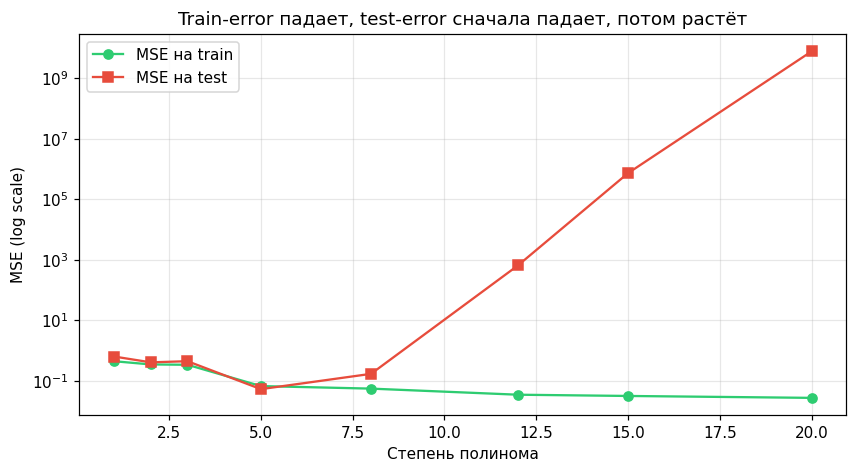


🧠 Классическая картина:
• degree=1–2: обе ошибки высокие → недообучение
• degree=3:   обе ошибки низкие → баланс
• degree≥8:   train→0, test растёт → переобучение (огромный разрыв)


In [63]:
# @title
# ========== Разделим данные на train/test и посмотрим на разрыв ==========

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

degrees = [1, 2, 3, 5, 8, 12, 15, 20]
train_mse, test_mse = [], []

for deg in degrees:
    pipe = make_pipeline(
        PolynomialFeatures(degree=deg, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )
    pipe.fit(X_train, y_train)
    train_mse.append(mean_squared_error(y_train, pipe.predict(X_train)))
    test_mse.append(mean_squared_error(y_test, pipe.predict(X_test)))

# Таблица
print(f"{'degree':>8} | {'MSE train':>12} | {'MSE test':>12} | {'разрыв':>10}")
print('-' * 52)
for d, tr, te in zip(degrees, train_mse, test_mse):
    print(f"{d:>8} | {tr:>12.4f} | {te:>12.4f} | {te - tr:>10.4f}")

# График
plt.figure(figsize=(9, 4.5))
plt.plot(degrees, train_mse, 'o-', label='MSE на train', color='#2ecc71')
plt.plot(degrees, test_mse,  's-', label='MSE на test',  color='#e74c3c')
plt.xlabel('Степень полинома'); plt.ylabel('MSE (log scale)')
plt.yscale('log')
plt.title('Train-error падает, test-error сначала падает, потом растёт')
plt.legend(); plt.grid(alpha=0.3, which='both')
plt.show()

print('\n🧠 Классическая картина:')
print('• degree=1–2: обе ошибки высокие → недообучение')
print('• degree=3:   обе ошибки низкие → баланс')
print('• degree≥8:   train→0, test растёт → переобучение (огромный разрыв)')

## 🩺 Как отличить недообучение от переобучения

| Симптом | Недообучение | Переобучение |
|---|---|---|
| MSE на train | Высокая | Очень низкая (≈0) |
| MSE на test | Высокая | Высокая |
| **Разрыв train ↔ test** | **Маленький** | **Огромный** |
| Что делать | Усложнить модель, добавить признаки | Упростить, регуляризация, больше данных |

> 🎯 **Главный диагностический признак переобучения — большой разрыв
> между качеством на train и на test.** Без test-выборки переобучение
> не поймать: train-метрика всегда будет «отличной».

## 🧩 Задание A. «Диагност моделей»

Вы — data scientist в клинике. Коллега прислал вам 3 кривые обучения (описаны ниже).
Ваша задача — поставить диагноз каждой модели и выписать «рецепт».

**Модель 1:** Train accuracy = 0.65, Validation accuracy = 0.63

**Модель 2:** Train accuracy = 0.999, Validation accuracy = 0.71

**Модель 3:** Train accuracy = 0.94, Validation accuracy = 0.92

Ответьте на вопросы (можно устно или в комментариях):

1. Какая модель страдает **недообучением**? Почему? Что посоветуете?
2. Какая модель **переобучена**? Почему? Что посоветуете?
3. Какая модель работает хорошо? Можно ли её ещё улучшить?

## ⚖️ Дилемма смещения-дисперсии

Полная ожидаемая ошибка модели раскладывается на три части:

$$
\text{Error} = \underbrace{\text{Bias}^2}_{\text{смещение}} \;+\;
\underbrace{\text{Variance}}_{\text{дисперсия}} \;+\;
\underbrace{\text{Noise}}_{\text{неустранимый шум}}
$$

| Компонента | Что это | Зависит от | Как уменьшить |
|---|---|---|---|
| **Bias** | Систематическая ошибка из-за слишком простых предположений | Сложность ↓ → Bias ↑ | Усложнить модель |
| **Variance** | Насколько модель «плавает» при смене train-выборки | Сложность ↑ → Variance ↑ | Упростить, регуляризация, больше данных |
| **Noise** | Внутренний шум данных | Не зависит от модели | Неустраним |

**Дилемма:**
- Сложнее модель → Bias ↓, но Variance ↑
- Проще модель  → Variance ↓, но Bias ↑

Задача — найти **золотую середину**, где Bias² + Variance минимальна.

## 🏹 Аналогия: стрельба из лука

- **Bias** — насколько стрелы *в среднем* смещены от центра
- **Variance** — насколько стрелы *разбросаны* между собой
- Хороший лучник — плотная кучка в центре

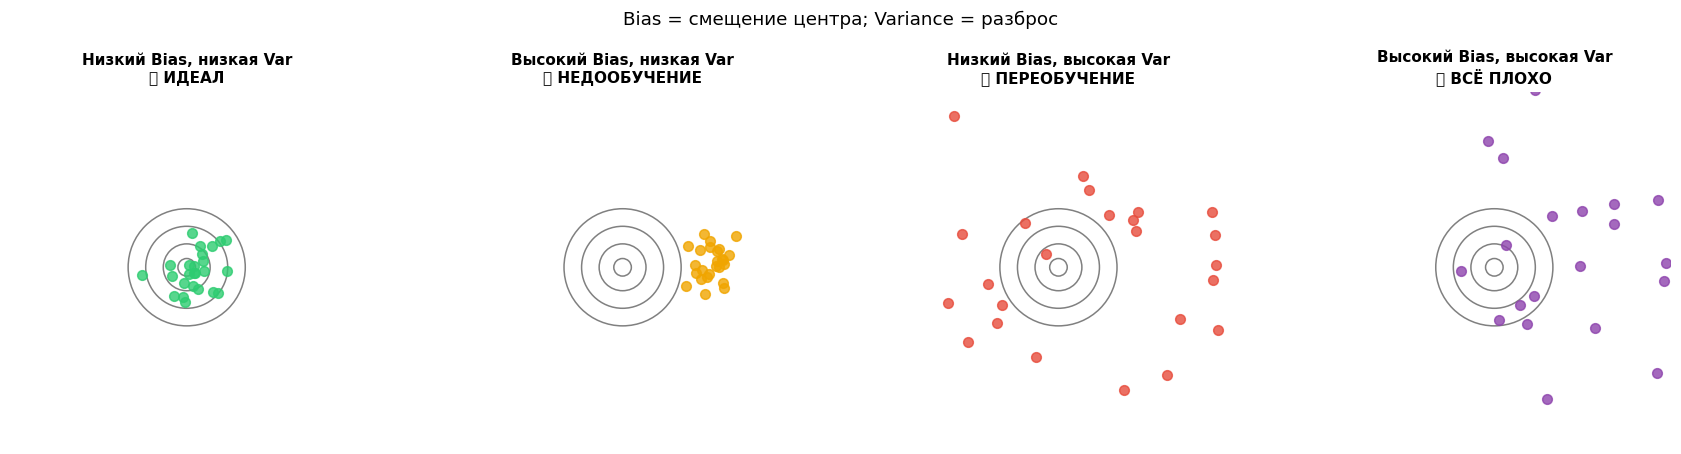

In [64]:
# @title
# ========== Bias vs Variance глазами лучника ==========
# Bias    — насколько кучка стрел смещена от центра
# Variance — насколько стрелы разбросаны между собой

np.random.seed(0)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
configs = [
    ('Низкий Bias, низкая Var\n✅ ИДЕАЛ',          0.0, 0.3, '#2ecc71'),
    ('Высокий Bias, низкая Var\n🟡 НЕДООБУЧЕНИЕ', 1.6, 0.3, '#f0a500'),
    ('Низкий Bias, высокая Var\n🔴 ПЕРЕОБУЧЕНИЕ', 0.0, 1.4, '#e74c3c'),
    ('Высокий Bias, высокая Var\n💀 ВСЁ ПЛОХО',   1.6, 1.4, '#8e44ad'),
]

for ax, (title, bias, var, col) in zip(axes, configs):
    # мишень
    for r in [1.0, 0.7, 0.4, 0.15]:
        ax.add_patch(Circle((0, 0), r, fill=False, ec='gray', lw=1))
    # «стрелы»
    ax.scatter(np.random.randn(25) * var + bias,
               np.random.randn(25) * var,
               color=col, s=40, alpha=0.8)
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
    ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(title, fontsize=10, fontweight='bold')

plt.suptitle('Bias = смещение центра; Variance = разброс', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

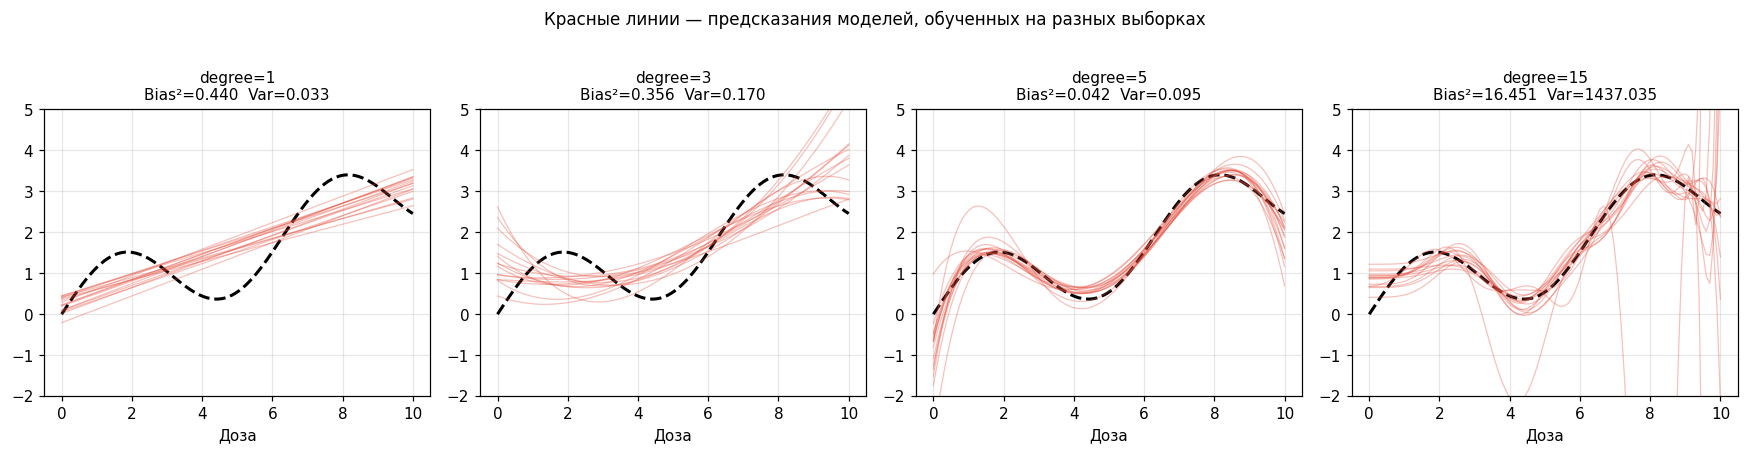

  degree |      Bias² |   Variance |  Bias²+Var |     +Noise
------------------------------------------------------------
       1 |     0.4399 |     0.0329 |     0.4728 |     0.5628
       3 |     0.3557 |     0.1695 |     0.5252 |     0.6152
       5 |     0.0417 |     0.0949 |     0.1367 |     0.2267
      15 |    16.4508 |  1437.0350 |  1453.4858 |  1453.5758


In [65]:
# @title
# ========== Оценка Bias² и Variance через bootstrap ==========
# Идея: много раз генерируем train-выборку из той же истинной зависимости,
# обучаем модель, смотрим (а) среднее предсказание и (б) разброс предсказаний.

np.random.seed(42)
n_points = 30
n_models = 100
x_eval = np.linspace(0, 10, 100).reshape(-1, 1)
true_eval = np.sin(x_eval.ravel()) + 0.3 * x_eval.ravel()

degrees_bv = [1, 3, 5, 15]
results = {}

for deg in degrees_bv:
    preds = []
    for _ in range(n_models):
        # новая train-выборка из той же истинной зависимости
        xb = np.sort(np.random.uniform(0, 10, n_points))
        yb = np.sin(xb) + 0.3 * xb + np.random.normal(0, 0.3, n_points)
        m = make_pipeline(
            PolynomialFeatures(degree=deg, include_bias=False),
            LinearRegression()
        ).fit(xb.reshape(-1, 1), yb)
        preds.append(m.predict(x_eval))
    preds = np.array(preds)

    avg_pred   = preds.mean(axis=0)
    bias_sq    = ((avg_pred - true_eval) ** 2).mean()
    variance   = preds.var(axis=0).mean()
    noise      = 0.3 ** 2   # известная дисперсия шума

    results[deg] = dict(bias_sq=bias_sq, variance=variance,
                        total=bias_sq + variance + noise)

# Визуализация
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, deg in zip(axes, degrees_bv):
    ax.plot(x_eval, true_eval, 'k--', lw=2, label='истина')
    # примеры предсказаний
    for _ in range(15):
        xb = np.sort(np.random.uniform(0, 10, n_points))
        yb = np.sin(xb) + 0.3 * xb + np.random.normal(0, 0.3, n_points)
        m = make_pipeline(PolynomialFeatures(degree=deg, include_bias=False),
                          LinearRegression()).fit(xb.reshape(-1, 1), yb)
        ax.plot(x_eval, m.predict(x_eval), color='#e74c3c',
                lw=0.8, alpha=0.35)
    r = results[deg]
    ax.set_title(f'degree={deg}\nBias²={r["bias_sq"]:.3f}  Var={r["variance"]:.3f}',
                 fontsize=10)
    ax.set_ylim(-2, 5); ax.grid(alpha=0.3)
    ax.set_xlabel('Доза')

plt.suptitle('Красные линии — предсказания моделей, обученных на разных выборках',
             fontsize=11, y=1.02)
plt.tight_layout()
plt.show()

# Числа
print(f"{'degree':>8} | {'Bias²':>10} | {'Variance':>10} | {'Bias²+Var':>10} | {'+Noise':>10}")
print('-' * 60)
for deg in degrees_bv:
    r = results[deg]
    print(f"{deg:>8} | {r['bias_sq']:>10.4f} | {r['variance']:>10.4f} | "
          f"{r['bias_sq']+r['variance']:>10.4f} | {r['total']:>10.4f}")

## 🛡️ Регуляризация — что это и зачем

В прошлой теме мы увидели: **переобученная модель** (degree=15) рисует
зигзаги, потому что у неё слишком много свободы — большие веса при
$x^{15}$, $x^{14}$ и т.д.

**Идея регуляризации простая:**

> Давайте **штрафовать** модель за большие веса. Тогда она не сможет
> «беситься» и будет вынуждена рисовать **плавные** кривые.

В функцию потерь добавляется слагаемое:

$$
\text{Loss}_{\text{Ridge}}(w) = \underbrace{\frac{1}{n}\sum_{i=1}^{n}\big(y_i - \hat{y}_i\big)^2}_{\text{MSE}} \;+\; \underbrace{\alpha \sum_{j=1}^{p} w_j^2}_{\text{штраф L2}}
$$

Для Lasso то же самое, но штраф — сумма **модулей**:

$$
\text{Loss}_{\text{Lasso}}(w) = \text{MSE} + \alpha \sum_{j=1}^{p} |w_j|
$$

Первое слагаемое — «хочу хорошо предсказывать на трейне».
Второе — «хочу маленькие веса».
Модель **балансирует** между ними, а `α` задаёт, насколько силён второй голос.

- $\alpha = 0$ → штрафа нет → можно переобучиться.
- $\alpha$ большой → штраф сильный → веса маленькие → модель простая.
- $\alpha$ оптимальный → **баланс**.

**Три вида штрафа** → три модели в sklearn:

| Название | Класс в sklearn | Что делает |
|---|---|---|
| **Ridge** (L2) | `Ridge(alpha=...)` | Уменьшает все веса, но не обнуляет |
| **Lasso** (L1) | `Lasso(alpha=...)` | Обнуляет часть весов (отбор признаков) |
| **ElasticNet** | `ElasticNet(alpha=..., l1_ratio=...)` | Смесь Ridge и Lasso |

> 🎯 Ключевое: **меняется одна строчка кода** — вместо `LinearRegression()`
> пишем `Ridge()`. Всё остальное (`fit`, `predict`) работает так же.

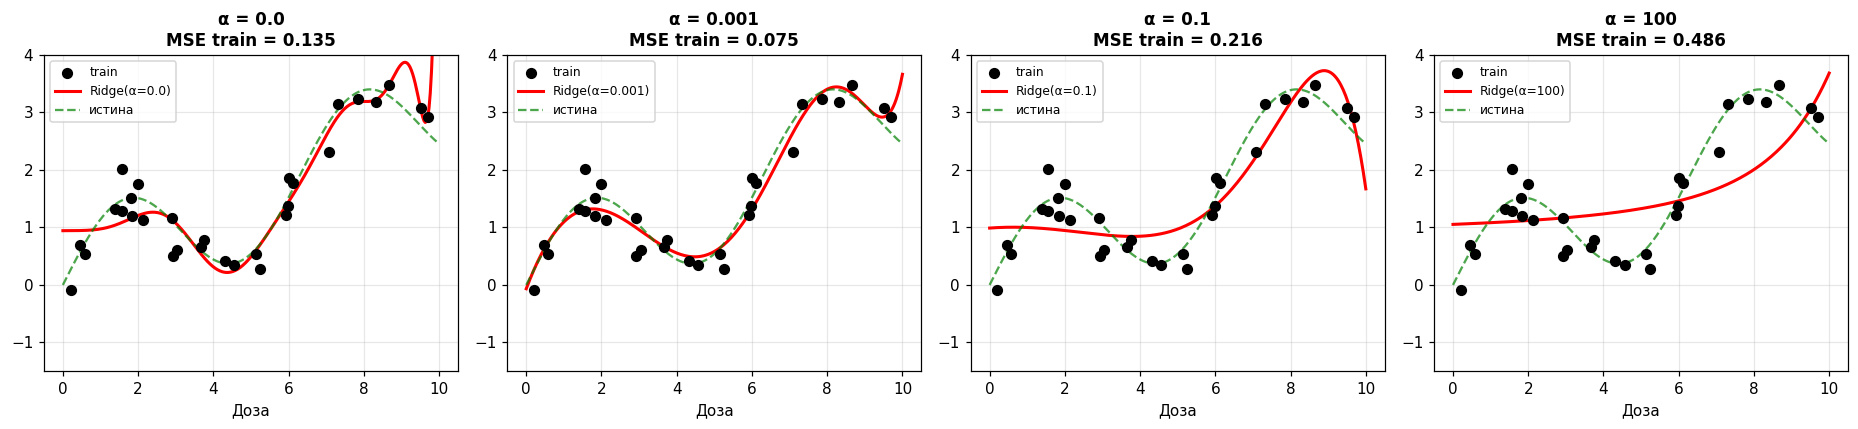

🧠 Что видно:
• α=0:        зигзаги, MSE≈0 → переобучение
• α=0.001:    ещё зигзаги, но помягче
• α=0.1:      плавная кривая, ловит форму → ЗОЛОТАЯ СЕРЕДИНА
• α=100:      почти прямая → штраф слишком большой (недообучение)

🎯 Один и тот же degree=15! Меняется только alpha.
   Регуляризация — ручка Bias/Variance без смены архитектуры.


In [66]:
# @title
# ========== Берём тот же пример, что и в прошлой теме ==========
# Полином degree=15 на 30 точках → зигзаги.
# А теперь добавим Ridge с разными alpha и посмотрим, что будет.

np.random.seed(42)
n = 30
dose = np.sort(np.random.uniform(0, 10, n))
effect = np.sin(dose) + 0.3 * dose + np.random.normal(0, 0.3, n)

X = dose.reshape(-1, 1)
y = effect
x_plot = np.linspace(0, 10, 300).reshape(-1, 1)
true_curve = np.sin(x_plot.ravel()) + 0.3 * x_plot.ravel()

# Разные alpha: 0 (без штрафа) → огромный штраф
alphas = [0.0, 0.001, 0.1, 100]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))

for ax, a in zip(axes, alphas):
    # degree=15 всегда, меняется только alpha
    if a == 0:
        model = make_pipeline(
            PolynomialFeatures(15, include_bias=False),
            LinearRegression()
        )
    else:
        model = make_pipeline(
            PolynomialFeatures(15, include_bias=False),
            StandardScaler(),          # обязательно! см. ниже
            Ridge(alpha=a)
        )
    model.fit(X, y)

    y_pred_train = model.predict(X)
    mse_train = mean_squared_error(y, y_pred_train)

    ax.scatter(X, y, s=40, c='black', zorder=5, label='train')
    ax.plot(x_plot, model.predict(x_plot), 'r-', lw=2,
            label=f'Ridge(α={a})')
    ax.plot(x_plot, true_curve, 'g--', lw=1.5, alpha=0.7, label='истина')
    ax.set_title(f'α = {a}\nMSE train = {mse_train:.3f}',
                 fontsize=11, fontweight='bold')
    ax.set_ylim(-1.5, 4); ax.set_xlabel('Доза')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()

print('🧠 Что видно:')
print('• α=0:        зигзаги, MSE≈0 → переобучение')
print('• α=0.001:    ещё зигзаги, но помягче')
print('• α=0.1:      плавная кривая, ловит форму → ЗОЛОТАЯ СЕРЕДИНА')
print('• α=100:      почти прямая → штраф слишком большой (недообучение)')
print()
print('🎯 Один и тот же degree=15! Меняется только alpha.')
print('   Регуляризация — ручка Bias/Variance без смены архитектуры.')

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import (
    LinearRegression,   # без регуляризации
    Ridge,              # L2
    Lasso,              # L1
    ElasticNet,         # L1 + L2
    RidgeCV,            # Ridge с автоподбором alpha
    LassoCV,            # Lasso с автоподбором alpha
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)
plt.rcParams['figure.dpi'] = 110
print('✅ Готово')

#Регуляризация на практике

Разберём регрессию (Ridge/Lasso/ElasticNet на данных)



ЧАСТЬ A. degree=15, разные модели (alpha=0.1 у всех регуляризованных)
модель                  train MSE   test MSE   вердикт
----------------------------------------------------------------------
LinearRegression           0.0817     0.1934   норм
Ridge(alpha=0.1)           0.0381     0.1389   норм
Lasso(alpha=0.001)         0.1642     0.2729   норм
ElasticNet(α=.01,l1=.5)     0.1663     0.2716   норм

ЧАСТЬ B. Ridge(degree=15): как alpha влияет на веса и ошибку
   alpha  train MSE   test MSE     max|w|
----------------------------------------------------------------------
  0.0001     0.0401     0.1442       3.38
   0.001     0.0383     0.1466       1.28
    0.01     0.0368     0.1474       0.74
     0.1     0.0381     0.1389       0.38
       1     0.0402     0.1453       0.18
      10     0.0461     0.1556       0.09
     100     0.0682     0.1714       0.03

👉 лучший alpha по test: 0.1  (test MSE = 0.1389)

ЧАСТЬ C. Lasso(degree=15): сколько весов обнулилось?
alpha= 0.001: обнулено

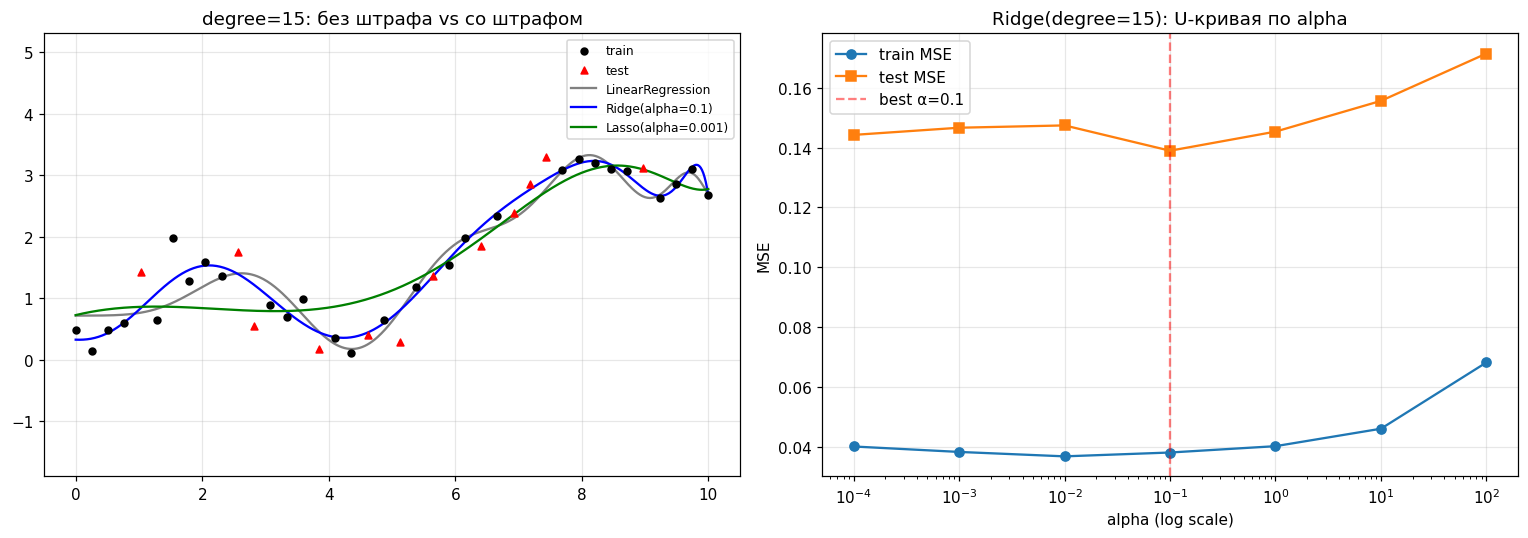

In [67]:
# @title
# ============================================================
# РЕГУЛЯРИЗАЦИЯ НА ДАННЫХ: LinearRegression vs Ridge vs Lasso
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# ---------- 1. ДАННЫЕ  ----------
np.random.seed(1)
x = np.linspace(0, 10, 40)
y = np.sin(x) + 0.3 * x + np.random.normal(0, 0.3, x.size)

X_tr, X_te, y_tr, y_te = train_test_split(
    x.reshape(-1, 1), y, test_size=0.3, random_state=0
)

# ---------- 2. ВСПОМОГАТЕЛЬНАЯ ФУНКЦИЯ ----------
def evaluate(name, model, degree=15):
    """Строит конвейер: полином degree → модель; возвращает train/test MSE."""
    pipe = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        model
    )
    pipe.fit(X_tr, y_tr)
    mse_tr = mean_squared_error(y_tr, pipe.predict(X_tr))
    mse_te = mean_squared_error(y_te, pipe.predict(X_te))
    return mse_tr, mse_te, pipe

# ============================================================
# ЧАСТЬ A. Один и тот же degree=15, разные модели
# ============================================================
print("=" * 70)
print("ЧАСТЬ A. degree=15, разные модели (alpha=0.1 у всех регуляризованных)")
print("=" * 70)
print(f"{'модель':<22} {'train MSE':>10} {'test MSE':>10}   вердикт")
print("-" * 70)

results = {}
for name, model in [
    ("LinearRegression", LinearRegression()),          # без штрафа
    ("Ridge(alpha=0.1)", Ridge(alpha=0.1)),            # L2
    ("Lasso(alpha=0.001)", Lasso(alpha=0.001)),        # L1
    ("ElasticNet(α=.01,l1=.5)", ElasticNet(alpha=0.01, l1_ratio=0.5)),
]:
    mse_tr, mse_te, pipe = evaluate(name, model)
    results[name] = pipe
    verdict = "переобучение" if mse_te > 10 * mse_tr else "норм"
    print(f"{name:<22} {mse_tr:>10.4f} {mse_te:>10.4f}   {verdict}")

# ============================================================
# ЧАСТЬ B. Эффект alpha (Ridge, degree=15)
# ============================================================
print("\n" + "=" * 70)
print("ЧАСТЬ B. Ridge(degree=15): как alpha влияет на веса и ошибку")
print("=" * 70)
print(f"{'alpha':>8} {'train MSE':>10} {'test MSE':>10} {'max|w|':>10}")
print("-" * 70)

alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
ridge_curve = []

for a in alphas:
    mse_tr, mse_te, pipe = evaluate(f"Ridge a={a}", Ridge(alpha=a))
    # max|w| — самый большой по модулю коэффициент: мера "бешенства" модели
    weights = pipe.named_steps["ridge"].coef_
    max_w = np.max(np.abs(weights))
    ridge_curve.append((a, mse_tr, mse_te, max_w))
    print(f"{a:>8} {mse_tr:>10.4f} {mse_te:>10.4f} {max_w:>10.2f}")

# Находим лучший alpha по test (в реальности — по CV!)
best = min(ridge_curve, key=lambda t: t[2])
print(f"\n👉 лучший alpha по test: {best[0]}  (test MSE = {best[2]:.4f})")

# ============================================================
# ЧАСТЬ C. Lasso обнуляет признаки (отбор признаков)
# ============================================================
print("\n" + "=" * 70)
print("ЧАСТЬ C. Lasso(degree=15): сколько весов обнулилось?")
print("=" * 70)

for a in [0.001, 0.01, 0.1, 1.0]:
    _, _, pipe = evaluate(f"Lasso a={a}", Lasso(alpha=a, max_iter=100_000))
    w = pipe.named_steps["lasso"].coef_
    zero_frac = (np.abs(w) < 1e-6).mean() * 100
    print(f"alpha={a:>6}: обнулено {zero_frac:5.1f}% весов  ({int(zero_frac/100*len(w))} из {len(w)})")

# ============================================================
# ЧАСТЬ D. ElasticNet: l1_ratio плавно переключает L1 ↔ L2
# ============================================================
print("\n" + "=" * 70)
print("ЧАСТЬ D. ElasticNet(alpha=0.01): эффект l1_ratio")
print("=" * 70)

for r in [0.0, 0.25, 0.5, 0.75, 1.0]:
    _, _, pipe = evaluate(f"EN r={r}", ElasticNet(alpha=0.01, l1_ratio=r, max_iter=100_000))
    w = pipe.named_steps["elasticnet"].coef_
    zero_frac = (np.abs(w) < 1e-6).mean() * 100
    label = "= Ridge" if r == 0 else ("= Lasso" if r == 1 else "")
    print(f"l1_ratio={r:>4}: обнулено {zero_frac:5.1f}% весов  {label}")

# ============================================================
# ЧАСТЬ E. ГРАФИК: как ведёт себя каждая модель
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# E1: кривые предсказаний на degree=15
xx = np.linspace(0, 10, 500).reshape(-1, 1)
ax = axes[0]
ax.scatter(X_tr, y_tr, color="black", s=20, label="train", zorder=5)
ax.scatter(X_te, y_te, color="red", s=20, marker="^", label="test", zorder=5)

for name, color in [
    ("LinearRegression", "gray"),
    ("Ridge(alpha=0.1)", "blue"),
    ("Lasso(alpha=0.001)", "green"),
]:
    ax.plot(xx, results[name].predict(xx), color=color, label=name)

ax.set_ylim(y.min() - 2, y.max() + 2)
ax.set_title("degree=15: без штрафа vs со штрафом")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# E2: U-кривая test MSE по alpha для Ridge
ax = axes[1]
a_arr = np.array([t[0] for t in ridge_curve])
tr_arr = np.array([t[1] for t in ridge_curve])
te_arr = np.array([t[2] for t in ridge_curve])
ax.plot(a_arr, tr_arr, "o-", label="train MSE")
ax.plot(a_arr, te_arr, "s-", label="test MSE")
ax.set_xscale("log")              # alpha меняется на порядки — логарифм по X
ax.set_xlabel("alpha (log scale)")
ax.set_ylabel("MSE")
ax.set_title("Ridge(degree=15): U-кривая по alpha")
ax.axvline(best[0], color="red", linestyle="--", alpha=0.5, label=f"best α={best[0]}")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [69]:
# ============================================================
# ОДИН КОНВЕЙЕР — ЧЕТЫРЕ МОДЕЛИ
# Меняем только одну строчку: LinearRegression → Ridge/Lasso/ElasticNet
# ============================================================
# ИДЕЯ: одни и те же полиномиальные признаки (degree=15) прогоняем
# через 4 разные линейные модели. Всё остальное (данные, признаки,
# train/test, метрика) — идентично. Разница в цифрах = эффект регуляризации.

import numpy as np
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# ---------- Данные ----------
np.random.seed(1)                          # фиксируем шум — пример воспроизводим
x = np.linspace(0, 10, 40)                 # 40 точек на [0, 10], один признак
y = np.sin(x) + 0.3 * x + np.random.normal(0, 0.3, x.size)
# истинная зависимость: синус + линейный тренд + гауссов шум σ=0.3.
# Модель должна выучить форму, но НЕ шум.

X_tr, X_te, y_tr, y_te = train_test_split(
    x.reshape(-1, 1), y, test_size=0.3, random_state=0
)
# reshape(-1, 1): sklearn ждёт 2D (n_samples, n_features)
# 70% train / 30% test — чтобы честно поймать переобучение

# ---------- Признаки: полином 15-й степени (вручную) ----------
# fit_transform на train — обучаемся строить признаки и сразу применяем.
# transform на test — ТОЛЬКО применяем, без повторного fit.
# Это защита от утечки: статистики признаков не подглядывают в тест.
poly = PolynomialFeatures(degree=15, include_bias=False)
X_tr_poly = poly.fit_transform(X_tr)       # [x, x², ..., x^15] — 15 столбцов
X_te_poly = poly.transform(X_te)           # те же 15 столбцов, без fit
print(f"Форма признаков: train={X_tr_poly.shape}, test={X_te_poly.shape}")

# Шапка таблицы результатов
print(f"\n{'модель':<24} {'train':>8} {'test':>8} {'sum|w|':>10}")
print("-" * 54)

# ============================================================
# 1) БЫЛО: LinearRegression — обычный МНК, без штрафа за большие веса
# ============================================================
# 15 признаков на ~28 train-точках — почти гарантированное переобучение:
# train-MSE маленький, test-MSE большой, веса «раздутые».
m = LinearRegression()
m.fit(X_tr_poly, y_tr)                     # <-- обучаем
mse_tr = mean_squared_error(y_tr, m.predict(X_tr_poly))
mse_te = mean_squared_error(y_te, m.predict(X_te_poly))
l1 = np.abs(m.coef_).sum()                 # сумма модулей весов — мера «раздутости»
print(f"{'LinearRegression':<24} {mse_tr:8.4f} {mse_te:8.4f} {l1:10.2f}")

# ============================================================
# 2) Ridge — L2-штраф: веса «сжимаются» к нулю, но не в ноль
# ============================================================
# alpha=0.1 — сила штрафа. Ожидаем: train-MSE чуть хуже, test — заметно лучше,
# sum|w| заметно меньше, чем у LinearRegression.
m = Ridge(alpha=0.1)                       # <-- меняем ОДНУ строчку
m.fit(X_tr_poly, y_tr)
mse_tr = mean_squared_error(y_tr, m.predict(X_tr_poly))
mse_te = mean_squared_error(y_te, m.predict(X_te_poly))
l1 = np.abs(m.coef_).sum()
print(f"{'Ridge(alpha=0.1)':<24} {mse_tr:8.4f} {mse_te:8.4f} {l1:10.2f}")

# ============================================================
# 3) Lasso — L1-штраф: часть коэффициентов становится РОВНО 0
# ============================================================
# Модель сама отбирает нужные признаки. Смотри на sum|w| — она сильно падает,
# и на счётчик обнулённых коэффициентов.
# alpha=0.001 — маленькая, чтобы не «убить» вообще все признаки.
# max_iter увеличиваем: у Lasso координатный спуск, иногда не сходится за дефолт.
m = Lasso(alpha=0.001, max_iter=10000)     # <-- меняем ОДНУ строчку
m.fit(X_tr_poly, y_tr)
mse_tr = mean_squared_error(y_tr, m.predict(X_tr_poly))
mse_te = mean_squared_error(y_te, m.predict(X_te_poly))
l1 = np.abs(m.coef_).sum()
n_zero = int(np.sum(m.coef_ == 0))         # сколько из 15 признаков Lasso занулил
print(f"{'Lasso(alpha=0.001)':<24} {mse_tr:8.4f} {mse_te:8.4f} {l1:10.2f}"
      f"   (обнулено {n_zero}/15)")

# ============================================================
# 4) ElasticNet — смесь L1 и L2
# ============================================================
# alpha — общая сила штрафа, l1_ratio=0.5 — поровну L1 и L2.
# Устойчивее чистого Lasso при коррелированных признаках
# (у полинома x, x², x³ сильно скоррелированы).
m = ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000)   # <-- меняем ОДНУ строчку
m.fit(X_tr_poly, y_tr)
mse_tr = mean_squared_error(y_tr, m.predict(X_tr_poly))
mse_te = mean_squared_error(y_te, m.predict(X_te_poly))
l1 = np.abs(m.coef_).sum()
n_zero = int(np.sum(m.coef_ == 0))
print(f"{'ElasticNet(0.01, 0.5)':<24} {mse_tr:8.4f} {mse_te:8.4f} {l1:10.2f}"
      f"   (обнулено {n_zero}/15)")

# ============================================================
# Что смотреть в выводе:
#   train ↔ test  — разрыв = переобучение. У LinearRegression он огромный,
#                   у регуляризованных моделей — меньше.
#   sum|w|        — насколько «раздуты» веса. Ridge их сжимает,
#                   Lasso/ElasticNet ещё и обнуляют часть.
# ============================================================

Форма признаков: train=(28, 15), test=(12, 15)

модель                      train     test     sum|w|
------------------------------------------------------
LinearRegression           0.0817   0.1934       0.09
Ridge(alpha=0.1)           0.0381   0.1389       1.15
Lasso(alpha=0.001)         0.0938   0.1629       1.95   (обнулено 0/15)
ElasticNet(0.01, 0.5)      0.0999   0.1719       1.61   (обнулено 0/15)


## 🪢 Почему Lasso обнуляет, а Ridge — нет? (интуиция)

Представьте, что каждый вес $w$ — это канат. Его тянут **две силы**:

- **Данные** тянут вес **от нуля** — «сделай меня побольше, я полезен для предсказания».
- **Штраф** тянет вес **к нулю** — «будь поменьше, ты усложняешь модель».

Кто победит — зависит от того, **насколько силён штраф**, когда вес уже почти ноль.

### Ridge (L2): «прощает» маленькие веса

Штраф $\propto w^2$. Чем меньше вес, тем **слабее** штраф его тянет.

- Вес $w = 0.01$ → сила штрафа $\approx 0.02$ — почти ноль.
- Данным достаточно **чуть-чуть** потянуть, и вес останется ненулевым.

➡️ Ridge уменьшает веса, но **никогда не доводит до нуля**: как только вес стал маленьким, штраф «отпускает», и данные удерживают его чуть выше нуля.

### Lasso (L1): «не прощает» никому

Штраф $\propto |w|$. Сила штрафа **одинаковая для любого веса** — что для $w = 10$, что для $w = 0.001$.

- Вес $w = 0.01$ → сила штрафа **1.0** — полная, как для большого веса.
- Если данные тянут **слабо** (признак малополезен), штраф **дотягивает вес до нуля**.

➡️ Lasso безжалостно **обнуляет** слабые веса. У веса нет «тихой гавани» чуть выше нуля — либо он достаточно большой, чтобы сопротивляться, либо его обнуляют.

> 🎯 **Ключевая мысль одной фразой:**
> - **Ridge**: «маленький вес — это дёшево, пусть живёт».
> - **Lasso**: «маленький вес — это всё равно затраты, лучше убей его полностью».

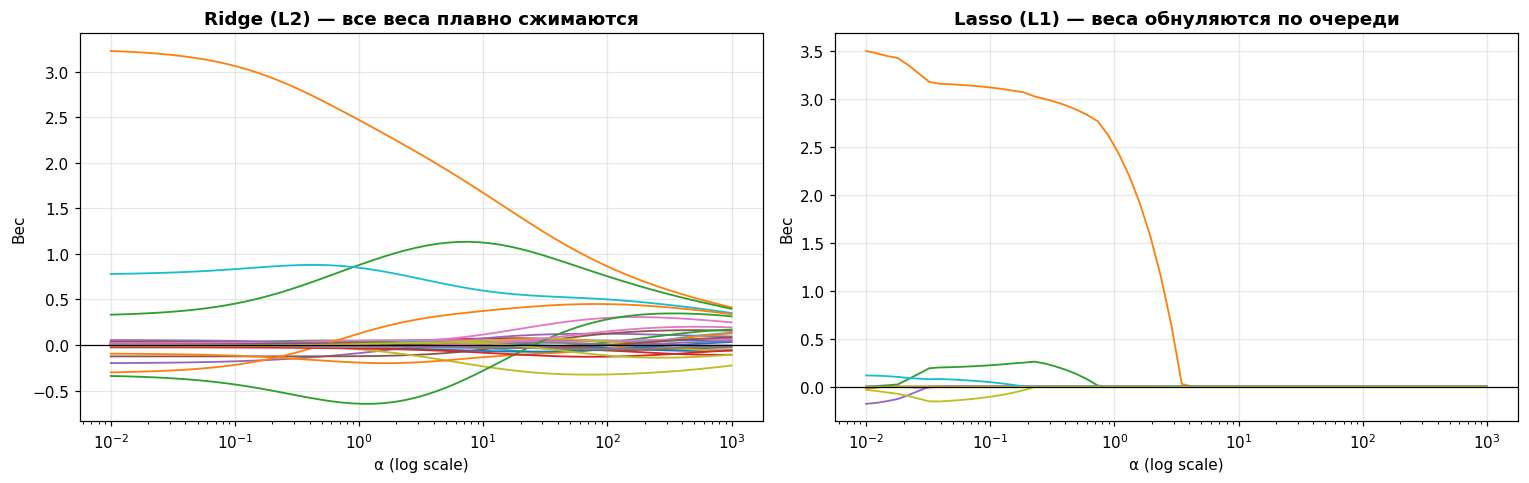

Lasso α=   0.1:  обнулено  86% весов  (осталось 4 признаков)
Lasso α=   1.0:  обнулено  97% весов  (осталось 1 признаков)
Lasso α=  10.0:  обнулено 100% весов  (осталось 0 признаков)
Lasso α= 100.0:  обнулено 100% весов  (осталось 0 признаков)

🧠 Ridge: ни один вес не становится ровно 0 — просто всё меньше и меньше.
   Lasso: чем больше α, тем больше весов → РОВНО 0 (отбор признаков).


In [70]:
# @title
# ========== Как меняются веса при увеличении alpha ==========
# Это гораздо информативнее, чем один bar chart.
# Видно, какие признаки «умирают» первыми, а какие держатся дольше.

from sklearn.datasets import load_breast_cancer
import pandas as pd

data = load_breast_cancer()
Xc = pd.DataFrame(data.data, columns=data.feature_names)
yc = Xc['mean radius']
Xc = Xc.drop(columns=['mean radius'])

# Масштабируем — ОБЯЗАТЕЛЬНО перед регуляризацией
from sklearn.preprocessing import StandardScaler
Xs = StandardScaler().fit_transform(Xc)

alphas = np.logspace(-2, 3, 60)          # от 0.01 до 1000
coefs_ridge, coefs_lasso = [], []

for a in alphas:
    coefs_ridge.append(Ridge(alpha=a).fit(Xs, yc).coef_)
    coefs_lasso.append(Lasso(alpha=a, max_iter=20000).fit(Xs, yc).coef_)

coefs_ridge = np.array(coefs_ridge)
coefs_lasso = np.array(coefs_lasso)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, coefs, name in zip(axes,
                            [coefs_ridge, coefs_lasso],
                            ['Ridge (L2) — все веса плавно сжимаются',
                             'Lasso (L1) — веса обнуляются по очереди']):
    ax.plot(alphas, coefs, lw=1.2)
    ax.set_xscale('log')
    ax.set_xlabel('α (log scale)')
    ax.set_ylabel('Вес')
    ax.set_title(name, fontweight='bold')
    ax.axhline(0, color='black', lw=0.8)
    ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()

# Сколько весов обнулил Lasso при большом alpha?
for a in [0.1, 1.0, 10.0, 100.0]:
    m = Lasso(alpha=a, max_iter=20000).fit(Xs, yc)
    zero_share = np.mean(np.abs(m.coef_) < 1e-6)
    print(f'Lasso α={a:>6}:  обнулено {zero_share:>4.0%} весов  '
          f'(осталось {np.sum(np.abs(m.coef_) >= 1e-6)} признаков)')

print()
print('🧠 Ridge: ни один вес не становится ровно 0 — просто всё меньше и меньше.')
print('   Lasso: чем больше α, тем больше весов → РОВНО 0 (отбор признаков).')

## ✅ Задачи

**1.** Врач хочет узнать, **какие из 50 анализов** действительно влияют на диагноз,
а какие — просто «шум». Какую модель выбрать: Ridge или Lasso?


---

**2.** Исследователь хочет **предсказать риск** по 50 анализам, но **все они
немного полезны** (например, разные измерения размера опухоли, сильно
коррелирующие между собой). Что выбрать?


---

**3.** Почему у Ridge ни один вес **никогда не становится ровно 0**?


---

**4.** Почему у Lasso веса **обнуляются**?


---

**5.** Что произойдёт с Lasso, если `alpha` сделать **очень большим**?


## 🧪 Train / Validation / Test — зачем три?

### Аналогия: экзамен с преподавателем

| Роль | В ML | В аналогии |
|---|---|---|
| **Train** | Модель учится | Домашка — по ней учимся |
| **Validation** | Подбираем гиперпараметры | Пробный экзамен — по нему проверяем, готовы ли |
| **Test** | Финальная честная оценка | Настоящий экзамен — видим его **один раз** |

### Зачем нужен отдельный validation?

Гиперпараметр — это «настройка» модели (`alpha` в Ridge).
Мы **перебираем варианты** и выбираем лучший. Но **по какой выборке**?

- Если по **train** → модель «запомнит» train и покажется отличной, но это обман.
- Если по **test** → мы **подсмотрим ответы** и test перестанет быть честным.
- Значит, нужен **третий** набор — **validation**. По нему выбираем, а test держим **до самого конца**.

> ⚠️ **Test трогаем ОДИН раз** — когда модель полностью готова.
> Каждое «а давайте попробуем ещё одну настройку на test» — это подглядывание.
> После нескольких таких попыток test становится бесполезен.

## 🚨 Мысленный эксперимент: почему test «портится»

Представьте, что вы подбираете `alpha` **по test**:

1. Пробуете `alpha=0.1` → test R² = 0.80
2. Пробуете `alpha=1.0` → test R² = 0.85  ← лучше!
3. Пробуете `alpha=10`  → test R² = 0.83
4. Оставляете `alpha=1.0`.

Казалось бы — всё честно, выбрали лучший по test. Но:

- Вы **видели test 3 раза**.
- Выбор `alpha=1.0` **зависит от test**.
- На новых, совсем невиданных данных результат может быть хуже.

Это называется **test leakage** (утечка test-а). Ошибка не в коде, а в **процедуре**.

> 🎯 Правило: **test — это «чёрный ящик»**. Достаём ответ **один раз**.
> Всё, что нужно подбирать — подбираем на **train+val**.

## ✂️ Ручной split: как делится в коде

Делим **дважды** — сначала отрезаем `test`, потом из оставшегося — `val`.

```
Весь датасет (100%)
│
├── Test (20%)            ← отрезаем ПЕРВЫМ, не трогаем до конца
│
└── Оставшиеся (80%)
    │
    ├── Train (60%)       ← на этом обучаемся
    │
    └── Validation (20%)  ← на этом подбираем гиперпараметры
```

В коде — **два вызова** `train_test_split`. Ключевой момент — `stratify`:
он сохраняет **пропорцию классов** во всех трёх выборках.
Без `stratify` в маленьком `val` может оказаться 90% одного класса — и оценка будет шумной.

In [71]:
# @title
# ========== Данные для всех упражнений ==========
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

# Реальные медицинские данные: рак груди (бинарная классификация)
data = load_breast_cancer()
X = data.data
y = data.target

print(f'Всего пациентов: {len(X)}')
print(f'Классы: {np.bincount(y)} (0 = злокачественная, 1 = доброкачественная)')

# ========== РУЧНОЙ SPLIT: train / val / test ==========

# Шаг 1: отрезаем test ПЕРВЫМ (20%), stratify сохраняет доли классов
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Шаг 2: из оставшихся 80% отделяем val (25% от temp = 20% от исходного)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

print('\n📊 Как поделились данные:')
print(f'   Train:       {len(X_train):>3} ({len(X_train)/len(X):.0%})  ← обучаемся')
print(f'   Validation:  {len(X_val):>3} ({len(X_val)/len(X):.0%})  ← подбираем C')
print(f'   Test:        {len(X_test):>3} ({len(X_test)/len(X):.0%})  ← финальная оценка')

# ⚠️ ВАЖНО: масштабирование fit ТОЛЬКО на train!
# fit на всём X или на X_val = утечка данных.
scaler = StandardScaler().fit(X_train)
X_train_sc = scaler.transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)

# ========== Шаг 3: перебор C на validation ==========
# Один гиперпараметр, одна метрика. test НЕ трогаем.
# Метку «лучшее» в цикле НЕ ставим — иначе она появляется у каждого нового рекорда.

print('\n🔍 Подбор C на validation:')
print(f'{"C":>8} | {"val accuracy":>13}')
print('-' * 24)

results = {}
for C in [0.01, 0.1, 1.0, 10.0, 100.0]:
    m = LogisticRegression(C=C, max_iter=5000, random_state=42)
    m.fit(X_train_sc, y_train)
    val_acc = m.score(X_val_sc, y_val)
    results[C] = val_acc
    print(f'{C:>8} | {val_acc:>13.3f}')

# Победителя объявляем ОДИН раз — после цикла
best_C = max(results, key=results.get)
best_val = results[best_C]
print(f'\n🏆 Лучший C = {best_C} (val accuracy = {best_val:.3f})')
print('   → валидация свою задачу выполнила, дальше её не используем')

# ========== Шаг 4: финальное обучение и оценка на TEST ==========
# Стандартная практика: после выбора C обучить модель на train+val
# (все данные, кроме test). Валидация уже отработала — её данные пускаем в дело.
# Так используется 80% датасета вместо 60%.

X_trainval_sc = np.vstack([X_train_sc, X_val_sc])
y_trainval    = np.concatenate([y_train, y_val])

final_model = LogisticRegression(C=best_C, max_iter=5000, random_state=42)
final_model.fit(X_trainval_sc, y_trainval)
test_acc = final_model.score(X_test_sc, y_test)

print(f'\n🎯 Финальная оценка на TEST (один раз): {test_acc:.3f}')
print(f'   обучено на train+val: {len(y_trainval)} пациентов')
print(f'   оценено на test:      {len(y_test)} пациентов')

# ========== Дополнительно: confusion matrix ==========
# Accuracy скрывает, КАК ошибается модель. На медицинских данных
# FN (пропустить злокачественную) опаснее FP (ложная тревога).
y_pred = final_model.predict(X_test_sc)
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f'\nConfusion matrix на test:')
print(f'   TN={tn}, FP={fp}')
print(f'   FN={fn}, TP={tp}')
print(f'   → пропущено злокачественных (FN): {fn}')
print(f'   → ложных тревог (FP):             {fp}')

Всего пациентов: 569
Классы: [212 357] (0 = злокачественная, 1 = доброкачественная)

📊 Как поделились данные:
   Train:       341 (60%)  ← обучаемся
   Validation:  114 (20%)  ← подбираем C
   Test:        114 (20%)  ← финальная оценка

🔍 Подбор C на validation:
       C |  val accuracy
------------------------
    0.01 |         0.939
     0.1 |         0.974
     1.0 |         0.991
    10.0 |         0.965
   100.0 |         0.965

🏆 Лучший C = 1.0 (val accuracy = 0.991)
   → валидация свою задачу выполнила, дальше её не используем

🎯 Финальная оценка на TEST (один раз): 0.982
   обучено на train+val: 455 пациентов
   оценено на test:      114 пациентов

Confusion matrix на test:
   TN=41, FP=1
   FN=1, TP=71
   → пропущено злокачественных (FN): 1
   → ложных тревог (FP):             1


## 🔄 А можно проще? Да — кросс-валидация

### Проблема ручного split

Мы уже видели: делим train / val / test — и подбираем гиперпараметр по val. Но:

- Результат **зависит от случая** — поменяли `random_state`, и «лучший C» может стать другим.
- `val` маленький (10–20%) → оценка **шумная**.
- Часть данных **выбрасывается** из обучения (val не участвует в fit).

**K-Fold кросс-валидация решает все три проблемы.**

### Идея

Вместо **одного** деления train/val — делим **k раз по-разному** и усредняем.

```
Train-выборка (без test!)
│
├── Fold 1:  [val][train train train train]  → acc₁
├── Fold 2:  [train][val][train train train] → acc₂
├── Fold 3:  [train train][val][train train] → acc₃
├── Fold 4:  [train train train][val][train] → acc₄
└── Fold 5:  [train train train train][val]  → acc₅

Итог: среднее acc ± стандартное отклонение
```

**Что происходит:**

1. Данные делятся на **k равных частей** (обычно `k=5` или `k=10`).
2. **k раз** обучаем модель: на `k-1` частях — обучение, на оставшейся 1 — проверка.
3. Каждая часть **ровно один раз** побывает в роли validation.
4. Итог — **среднее** и **разброс** по k фолдам.

### Что это даёт

| Проблема ручного split | Решение через K-Fold |
|---|---|
| Зависит от случая | Все данные k раз побывают в val — оценка стабильнее |
| Маленький val → шум | Каждый раз val = 1/k данных, но их k → усреднение |
| Часть данных не учится | Каждая точка k−1 раз участвует в обучении |

> 🎯 **K-Fold = «честная оценка» без выделения отдельного val-сета.**
> Test по-прежнему отрезаем отдельно и трогаем один раз.


##K-Fold «в одну строчку»:

In [72]:
# ========== Тот же K-Fold, но через cross_val_score ==========
# Внутри cross_val_score — цикл по фолдам, который мы только что делали руками.

from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

# Данные
data = load_breast_cancer()
X, y = data.data, data.target

# Отрезаем test (один раз!)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Pipeline: scaler внутри — без утечки
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1.0, max_iter=5000, random_state=42)
)

# 5-fold CV — ОДНА строка
scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')

print(f'Оценки по фолдам: {np.round(scores, 4)}')
print(f'Среднее:          {scores.mean():.4f}')
print(f'Std (разброс):    {scores.std():.4f}')
print()
print('🧠 Что мы получили:')
print('   • 5 оценок — по одной на каждый фолд')
print('   • Среднее — честная оценка качества')
print('   • Std — насколько оценка стабильна')
print('   • Модель обучалась 5 раз, но test не трогали ни разу')

Оценки по фолдам: [0.967 0.978 0.967 1.    0.989]
Среднее:          0.9802
Std (разброс):    0.0128

🧠 Что мы получили:
   • 5 оценок — по одной на каждый фолд
   • Среднее — честная оценка качества
   • Std — насколько оценка стабильна
   • Модель обучалась 5 раз, но test не трогали ни разу


## 🎯 Stratified K-Fold — когда классы несбалансированы

### Проблема обычного K-Fold

Обычный `KFold` делит **как попало** — следит только за тем, чтобы фолды были
одинакового размера. **Пропорция классов** внутри фолдов может «плясать».

Пример: в выборке 80% здоровых, 20% больных.

**Обычный KFold** может дать такой фолд:
- Fold 1 (val): 10 здоровых, **0 больных** → модель никогда не видит больных в val → оценка врёт.
- Fold 3 (train): 60 здоровых, 10 больных → модели **не хватает** больных для обучения.

**Это катастрофа для маленьких выборок и редких классов** (а в медицине редкий класс = больные — это и есть самое важное!).

### Решение: StratifiedKFold

**Stratified** = «расслоённый». Он делит данные так, чтобы **в каждом фолде
пропорция классов была такой же, как в исходной выборке**.

```
Исходные данные: 80% здоровых, 20% больных (например, 400 + 100)
       │
       ├── Fold 1: 80 здоровых + 20 больных  ← та же пропорция!
       ├── Fold 2: 80 здоровых + 20 больных  ← та же пропорция!
       ├── Fold 3: 80 здоровых + 20 больных
       ├── Fold 4: 80 здоровых + 20 больных
       └── Fold 5: 80 здоровых + 20 больных
```

**В каждом фолде — та же доля классов, что и во всей выборке.**

### Когда использовать

| Задача | Что использовать |
|---|---|
| **Классификация** (бинарная или мульти) | ✅ **`StratifiedKFold`** (или `cv=5` в `cross_val_score` — он сам стратифицирует) |
| **Регрессия** | `KFold` (классов нет) |
| **Временные ряды** | `TimeSeriesSplit` (нельзя перемешивать!) |

> 🎯 **Правило:** в классификации **всегда** используйте stratify.  
> Хорошая новость: `cross_val_score(..., cv=5)` и `GridSearchCV(..., cv=5)`
> **автоматически** используют `StratifiedKFold` для классификаторов.
> Но понимать, что внутри, — обязательно.

In [73]:
# ========== Сравнение KFold и StratifiedKFold на несбалансированных данных ==========
from sklearn.model_selection import KFold, StratifiedKFold
import numpy as np

# Несбалансированные данные: 90% класса 0, 10% класса 1
np.random.seed(42)
y_imbalanced = np.array([0] * 90 + [1] * 10)
X_dummy = np.arange(len(y_imbalanced)).reshape(-1, 1)

print('📊 Исходные данные:')
print(f'   Класс 0: {np.sum(y_imbalanced==0)} (90%)')
print(f'   Класс 1: {np.sum(y_imbalanced==1)} (10%)')
print(f'   Всего:   {len(y_imbalanced)}\n')

# === Обычный KFold ===
print('❌ KFold (без stratify):')
kf = KFold(n_splits=5, shuffle=True, random_state=0)
for i, (_, val_idx) in enumerate(kf.split(X_dummy, y_imbalanced), 1):
    val_classes = y_imbalanced[val_idx]
    n0 = np.sum(val_classes == 0)
    n1 = np.sum(val_classes == 1)
    print(f'   Fold {i}: {n0} класса 0 + {n1} класса 1 '
          f'(доля класса 1 = {n1/len(val_classes):.0%})')

# === StratifiedKFold ===
print('\n✅ StratifiedKFold (со stratify):')
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
for i, (_, val_idx) in enumerate(skf.split(X_dummy, y_imbalanced), 1):
    val_classes = y_imbalanced[val_idx]
    n0 = np.sum(val_classes == 0)
    n1 = np.sum(val_classes == 1)
    print(f'   Fold {i}: {n0} класса 0 + {n1} класса 1 '
          f'(доля класса 1 = {n1/len(val_classes):.0%})')

print('\n🧠 Видно разницу:')
print('   • KFold:           доля класса 1 в фолдах ПЛЯШЕТ (0% … 20%)')
print('   • StratifiedKFold: доля класса 1 ВСЕГДА ≈ 10%, как в исходных данных')

📊 Исходные данные:
   Класс 0: 90 (90%)
   Класс 1: 10 (10%)
   Всего:   100

❌ KFold (без stratify):
   Fold 1: 17 класса 0 + 3 класса 1 (доля класса 1 = 15%)
   Fold 2: 18 класса 0 + 2 класса 1 (доля класса 1 = 10%)
   Fold 3: 19 класса 0 + 1 класса 1 (доля класса 1 = 5%)
   Fold 4: 17 класса 0 + 3 класса 1 (доля класса 1 = 15%)
   Fold 5: 19 класса 0 + 1 класса 1 (доля класса 1 = 5%)

✅ StratifiedKFold (со stratify):
   Fold 1: 18 класса 0 + 2 класса 1 (доля класса 1 = 10%)
   Fold 2: 18 класса 0 + 2 класса 1 (доля класса 1 = 10%)
   Fold 3: 18 класса 0 + 2 класса 1 (доля класса 1 = 10%)
   Fold 4: 18 класса 0 + 2 класса 1 (доля класса 1 = 10%)
   Fold 5: 18 класса 0 + 2 класса 1 (доля класса 1 = 10%)

🧠 Видно разницу:
   • KFold:           доля класса 1 в фолдах ПЛЯШЕТ (0% … 20%)
   • StratifiedKFold: доля класса 1 ВСЕГДА ≈ 10%, как в исходных данных


#Как вызвать StratifiedKFold явно

In [74]:
# ========== Явный StratifiedKFold ==========
# Иногда нужен полный контроль: например, своя логика в цикле по фолдам.

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_accuracies = []

for fold_i, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    # Train/val на этом фолде
    X_fold_train, X_fold_val = X_train[train_idx], X_train[val_idx]
    y_fold_train, y_fold_val = y_train[train_idx], y_train[val_idx]

    # Pipeline (scaler fit на train-фолде!)
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1.0, max_iter=5000, random_state=42)
    )
    model.fit(X_fold_train, y_fold_train)
    val_acc = model.score(X_fold_val, y_fold_val)
    fold_accuracies.append(val_acc)

    print(f'Fold {fold_i}: val accuracy = {val_acc:.4f} '
          f'(в val: {np.sum(y_fold_val==0)} + {np.sum(y_fold_val==1)})')

print(f'\n📊 Среднее:  {np.mean(fold_accuracies):.4f}')
print(f'   Std:      {np.std(fold_accuracies):.4f}')
print()
print('🧠 Это ТО ЖЕ САМОЕ, что делает cross_val_score, только вручную.')
print('   Такой явный цикл нужен, когда нужно сохранять модели фолдов,')
print('   собирать OOF-предсказания или встраивать свою логику.')

Fold 1: val accuracy = 0.9670 (в val: 34 + 57)
Fold 2: val accuracy = 0.9890 (в val: 34 + 57)
Fold 3: val accuracy = 0.9780 (в val: 34 + 57)
Fold 4: val accuracy = 0.9890 (в val: 34 + 57)
Fold 5: val accuracy = 0.9670 (в val: 34 + 57)

📊 Среднее:  0.9780
   Std:      0.0098

🧠 Это ТО ЖЕ САМОЕ, что делает cross_val_score, только вручную.
   Такой явный цикл нужен, когда нужно сохранять модели фолдов,
   собирать OOF-предсказания или встраивать свою логику.


In [76]:
# ========== МИНИ-ЗАДАНИЕ ==========
# Ниже — три вопроса.

print('Вопрос 1:')
print('  В выборке 95% здоровых и 5% больных.')
print('  Модель показывает accuracy = 0.95 на каждом фолде CV.')
print('  Что не так с этой оценкой?\n')

print('Вопрос 2:')
print('  У нас 100 пациентов, из них 5 больных. Хотим 5-fold CV.')
print('  Что произойдёт с обычным KFold? Со StratifiedKFold?\n')

# === Проверим экспериментально ===
print('─' * 60)
print('🔬 ЭКСПЕРИМЕНТ к вопросу 1:\n')

# Данные: 95% класса 0, 5% класса 1
np.random.seed(0)
y_demo = np.array([0] * 95 + [1] * 5)
X_demo = np.random.randn(100, 3)   # случайные признаки — сигнала НЕТ

model_dummy = LogisticRegression(max_iter=5000, random_state=42)
scores = cross_val_score(model_dummy, X_demo, y_demo, cv=5, scoring='accuracy')

print(f'Accuracy по фолдам: {np.round(scores, 3)}')
print(f'Средняя accuracy:  {scores.mean():.3f}')
print()

Вопрос 1:
  В выборке 95% здоровых и 5% больных.
  Модель показывает accuracy = 0.95 на каждом фолде CV.
  Что не так с этой оценкой?

Вопрос 2:
  У нас 100 пациентов, из них 5 больных. Хотим 5-fold CV.
  Что произойдёт с обычным KFold? Со StratifiedKFold?

────────────────────────────────────────────────────────────
🔬 ЭКСПЕРИМЕНТ к вопросу 1:

Accuracy по фолдам: [0.95 0.95 0.95 0.95 0.95]
Средняя accuracy:  0.950

